In [1]:
##########################################################################################################
# read data from a pedestal file to look for misnumbered chips or those issuing invalid parity packets
##########################################################################################################

import h5py
import matplotlib.pyplot as plt
import yaml
import numpy as np
import argparse
import json
import tqdm
import io
import tarfile
import os
import math

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import cm
from matplotlib.colors import Normalize
from statistics import mean, mode, stdev
from pathlib import Path
from datetime import datetime

##########################################################
# Initialize parameters  
##########################################################

# input the filename and corresponding asic directory (include the location)
filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_ped_set2_10tiles_480s_220vref_4.hdf5"
asic_dir = "/data/v3/10x16/set2_10_tile_tests_20260312/asic_configs/cold/ped_set2_10tiles_220vref_no_hot_chan/"

# tile numbers (or the subset you wish to test) recorded in this data file
#tiles = [1,2,3,4,5,6,7,8,9,10]
tiles = [10]

#this script can only run 1 io_group (or pacman) at a time
ig = 1

#Setting verbose = True will print out various pieces of chip-level or packet-level information¶
verbose = False

#the following values are just being initialized to zero
nenabled_chips = 0 
ndisabled_channels = [0 for chp in range(256)] 
network = {} 
first_tile = True
distance_btwn_invalid = [[] for chp in range(256)]

# background: packet dataset attributes: 
# ('io_group', 'io_channel', 'chip_id', 'packet_type', 'downstream_marker', 'parity', 'valid_parity', 'channel_id', 
# 'timestamp', 'dataword', 'trigger_type', 'local_fifo', 'shared_fifo', 'register_address', 'register_data', 'direction', 
# 'local_fifo_events', 'shared_fifo_events', 'counter', 'fifo_diagnostics_enabled', 'first_packet', 'receipt_timestamp')

In [2]:
# given a raw data file, this code obtains the dictionary "network" which records the 
# chips in each io_channel hydra network as it was configured for that file
def extract_network(name):

    global network

    for file in os.listdir(name+'/hydra_network'):
        with open(name+'/hydra_network/'+file) as f: d=json.load(f)
    
        for io_group in d['network'].keys():
            if io_group in ['miso_us_uart_map', 'miso_ds_uart_map', 'mosi_uart_map']: continue
            if not int(io_group) in network.keys(): network[int(io_group)]={}
            for io_channel in d['network'][io_group].keys():
                if not int(io_channel) in network[int(io_group)].keys(): network[int(io_group)][int(io_channel)] = []
                for i in range(len(d['network'][io_group][io_channel]['nodes'])-1):
                    network[int(io_group)][int(io_channel)].append(d['network'][io_group][io_channel]['nodes'][i+1]['chip_id'])
                #print(f"\nIO_channel {int(io_channel)} chips: {network[int(io_group)][int(io_channel)]}")

    return

In [3]:
# from the tar file information get the dictionary "configs" that contains configuration 
# information stored at the beginning of each 3-minute data file. Configuration Keys: 
# dict_keys(['threshold_global', 'ref_current_trim', 'vref_dac', 'vcm_dac', 'adc_hold_delay', 'chip_id', 
# 'enable_piso_upstream', 'enable_piso_downstream', 'enable_posi', 'enable_periodic_reset', 'enable_rolling_periodic_reset', 
# 'channel_mask', 'periodic_reset_cycles', 'tx_slices0', 'tx_slices1', 'tx_slices2', 'tx_slices3', 'i_tx_diff0', 
# 'i_tx_diff1', 'i_tx_diff2', 'i_tx_diff3', 'r_term0', 'r_term1', 'r_term2', 'r_term3', 'csa_enable', 'pixel_trim_dac'])

def get_configs(name):
    configs = {}
    
    for file in os.listdir(name+'/asic_configs'):
        with open(name+'/asic_configs/'+file) as f: d=json.load(f)
        configs[d['meta']['CHIP_KEY']] = { reg : d[reg] for reg in d.keys() if not reg=='meta' }
        
    return configs

In [4]:
# each 3-minute raw data file has a set of keys: ['_header', 'configs', 'daq_configs', 
# 'messages', 'packets']. A tar file (stored in key = "daq_configs") contains 
# configuration settings for each chip in the charge read-out system at the beginning
# of the file's 10-minute time period. It also contains configuration details. 
# This code unpacks the tar file
def extract_config(file):
    
    with h5py.File(file) as h5f:   
        #print(f'\tKeys in datafile {file}:\n{h5f.keys()}')
        buf = io.BytesIO(np.array(h5f['daq_configs']).data) # the tar file is stored under the key 'daq_configs'

    extract=True
    with tarfile.open(fileobj=buf) as tarf:
        name = tarf.getmembers()[0].name 
        if Path(name).exists(): # if the tar file has already been extracted there's no need to do it again
            extract=False
        if extract: tarf.extractall() 
    return name

In [5]:
''' 

This is the list of possible io_channels in each tile. It does not tell you if these
io_channels were enabled

'''

def get_io_channels(tile):

    io_ch_per_tile = [
        [],
        [1,2,3,4],
        [5,6,7,8],
        [9,10,11,12],
        [13,14,15,16],
        [17,18,19,20],
        [21,22,23,24],
        [25,26,27,28],
        [29,30,31,32],
        [33,34,35,36],
        [37,38,39,40]
        ]
    
    return io_ch_per_tile[tile]


In [6]:
def get_data(filename, tile, ig):
    
    global data_pkts, ndisabled_channels, first_tile, network, verbose
    
    data_chips, ndata_by_chip_list, ndata_by_channel_list, npkts = [], [], [], 0
    ndata_by_chip    = [0 for chip in range(256)]
    ndata_by_channel = [[0 for chan in range(64)] for chip in range(256)]
    
    invalid_chips, ninvalid, ninvalid_by_chip = [], 0, []
    unique_chips  = []
    nsyncs = []
    misnumbered_chips = False
    debug_count = 0
    n_misnumbered_channels = 0

    # read packet data from initialized file name
    f = h5py.File(filename, 'r')
    packets = f['packets'][:]
    unixtime = f['packets'][:]['timestamp'][f['packets']
                                            [:]['packet_type'] == 4]
    livetime = np.max(unixtime)-np.min(unixtime)
    
    # create arrays of data packets
    data_mask     = f['packets'][:]['packet_type']  == 1
    data_pkts     = packets[data_mask]

    # identify io_channels with data packets in this data file
    unique_io_channels = list(dict.fromkeys(data_pkts['io_channel'][:]))
    unique_io_channels = sorted(unique_io_channels)

    # print out run statistics for the file
    if first_tile:
        npkts         = len(data_pkts) 
        print(f"{npkts:,} data packets for tile {tile} arriving at an average rate of {npkts/livetime:.0f} pkts/s over {livetime}s of data taking") 

        # get the hydra network configuration for each io_channel for the first file
        config_dir = extract_config(filename)

        # extract the dictionary "network" which stores information about the hydra network configuration
        extract_network(config_dir)
        
        first_tile = False

    # get a list of the io_channels that could be enabled for a given tile, and then determine which
    # ones were enabled
    io_channel_ids = get_io_channels(tile)
    enabled_io_channels = list(set(io_channel_ids) & set(unique_io_channels))
    
    print(f"\n\n############################ Tile {tile} Run Statistics ###################################")  
    print(f'\nio_channels enabled for tile {tile}: {enabled_io_channels}')

    # mask for the chosen tile
    tile_mask = (data_pkts['io_channel']== io_channel_ids[0]) | (data_pkts['io_channel']== io_channel_ids[1]) | (data_pkts['io_channel']== io_channel_ids[2]) | (data_pkts['io_channel']== io_channel_ids[3])
    data_pkts = data_pkts[tile_mask]

    # identify chips on this tile with data packets
    unique_chips = list(dict.fromkeys(data_pkts['chip_id'][:]))
    
    npkts = len(data_pkts) 

    if npkts ==0: 
        print(f'There are no data packets for tile {tile}')        
        return
    
#########################################################
# identify misnumbered chips
##########################################################
    
    data_chips = data_pkts['chip_id'][:]

    unique_chips = list(dict.fromkeys(data_chips))
 
    print(f'\n\n---------------------- Tile {tile} Results -----------------------------------')
    
    if len(unique_chips) == 160:
        print(f'\n{len(unique_chips)} chips were recorded from Tile {tile}')
    else:
        print(f'\nPROBLEM: {len(unique_chips)} chips were recorded from Tile {tile}. There should be 160 unless a chip has been disabled') 
    
    for chip in unique_chips:

        wrong_ioch_chip = False

        chip_mask = data_pkts['chip_id'] == chip
        chip_pkts = data_pkts[chip_mask]

        chip_ioch  = chip_pkts['io_channel'][:]
        chip_chans = chip_pkts['channel_id'][:]

        unique_iochs = list(dict.fromkeys(chip_ioch))
        
        # create list used to determine mode of # pkts per chip
        ndata_by_chip[chip] = len(chip_pkts)
        ndata_by_chip_list.append(ndata_by_chip[chip])

        unique_channels = list(dict.fromkeys(chip_chans))
        
        # create list used to determine mode of # pkts per channel
        for chan in unique_channels:
            chan_mask = chip_pkts['channel_id'] == chan
            chan_pkts = chip_pkts[chan_mask]

            # count the # of packets by channel
            ndata_by_channel[chip][chan] = len(chan_pkts)
            if ndata_by_channel[chip][chan] > 0:
    
                ndata_by_channel_list.append(ndata_by_channel[chip][chan])

            # look for channels with packets that flipped a chip ID bit
            for ioch in unique_iochs:
                    
                if chip not in network[ig][ioch]:
                    n_misnumbered_channels +=  1
                    wrong_ioch_chip = True
        
        # print a message for chips in the wrong io_channel        
        if wrong_ioch_chip:
            print(f'\nChip {chip} on Tile {tile} should not be in IO_channel {ioch}. It is probably misnumbered.\n')
        
        # look for chips that are outside of the acceptable chip ID range
        if chip not in range(11,171):

            # count the number of channels that are flipping chip ID bits
            n_misnumbered_channels += len( list(dict.fromkeys(chip_pkts['channel_id'][:])) )
            
            misnumbered_chips = True

            valid_percent   = 100 * chip_pkts['valid_parity'][:].tolist().count(1) / ndata_by_chip[chip]
            invalid_percent = 100 * chip_pkts['valid_parity'][:].tolist().count(0) / ndata_by_chip[chip]
                
            print(f'\tMisnumbered Chip {chip} has {ndata_by_chip[chip]} data packets, {valid_percent:.1f}% / {invalid_percent:.1f} have valid / invalid parity') 

    print(f"\n{n_misnumbered_channels} channels with misnumbered chip ID's were detected\n")
    
#################################
# identify invalid chips
#################################

    print(f'\n\n>>>>> Looking for Invalid Parity')

    invalid_mask  = data_pkts['valid_parity'] == 0
    invalid_pkts  = data_pkts[invalid_mask]
    ninvalid      = len(invalid_pkts)
    
    print(f"\t# of invalid packets = {ninvalid}\t or {100 * ninvalid/npkts:.1f}% of all data packets on Tile {tile}")
    
    # histogram any chips with invalid packets
    if ninvalid > 0:
    
        invalid_chips = invalid_pkts['chip_id'][:]
        
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.hist(invalid_chips, bins=256)
        ax.set_title(f'Invalid Parity Packet Count per Chip on Tile {tile}\nTest of v3a Tile #{tile} from Pacman #{ig}')
        ax.set_xlabel(f'Chip ID')
        ax.set_yscale('log')
        ax.set_ylabel(f'Invalid Packet Count')
        plt.show 

        unique_chips = list(dict.fromkeys(invalid_chips))
        print(f'\nCount of Invalid Parity packets by chip on Tile {tile}:')

        for chip in unique_chips:

            n_invalid_messages = 0
            
            ninvalid_by_chip = invalid_chips.tolist().count(chip)
            percent_invalid = 100*ninvalid_by_chip/ndata_by_chip[chip]
            
            print(f'\tTILE {tile} CHIP {chip}: {ninvalid_by_chip} \tor {percent_invalid:.2f}% of the {ndata_by_chip[chip]} packets from this chip')

            chip_mask = data_pkts['chip_id'] == chip
            chip_pkts = data_pkts[chip_mask]
    
            chip_valid_parity  = chip_pkts['valid_parity'][:]

            last_pkt = 0
                       
            for pkt in range(len(chip_valid_parity)):
                if chip_valid_parity[pkt] == 0:

                    n_invalid_messages += 1

                    if n_invalid_messages > 16:
                        continue
                          
                    if verbose:
                        print(f'\t\tChip {chip}: Invalid parity on packet {pkt} out of {len(chip_valid_parity)} total packets')
                    
                    if last_pkt > 0:
                        if verbose:
                            print(f'\t\t\t distance between invalid packets = {pkt-last_pkt}')
                        distance_btwn_invalid[chip].append(pkt-last_pkt)
                    last_pkt = pkt

            fig, ax = plt.subplots(figsize=(6, 3))
            ax.hist(distance_btwn_invalid[chip])
            ax.set_title(f'Packet Count Between Invalid Packets on Tile-Chip {tile}-{chip}\n{percent_invalid:.2f}% of Chip {chip} Pkts are Invalid, Test of Tile #{tile} on Pacman #{ig}')
            ax.set_xlabel(f'Packet Count Between Invalid Packets')
            ax.set_yscale('log')
            ax.set_ylabel(f'# of Instances')
            plt.show 
    
    return 

######################## Run Statistics ############################################

Data File /data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_ped_set2_10tiles_480s_220vref_4.hdf5:
49,708,676 data packets for tile 10 arriving at an average rate of 106215 pkts/s over 468s of data taking


############################ Tile 10 Run Statistics ###################################

io_channels enabled for tile 10: [37, 38, 39]


---------------------- Tile 10 Results -----------------------------------

PROBLEM: 159 chips were recorded from Tile 10. There should be 160 unless a chip has been disabled

0 channels with misnumbered chip ID's were detected



>>>>> Looking for Invalid Parity
	# of invalid packets = 514607	 or 10.4% of all data packets on Tile 10

Count of Invalid Parity packets by chip on Tile 10:
	TILE 10 CHIP 168: 15594 	or 50.00% of the 31189 packets from this chip
	TILE 10 CHIP 158: 15596 	or 50.00% of the 31189 packets from this chip
	TILE 10 CHIP 166: 1559

/tmp/ipykernel_1994114/1511943876.py:196: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(6, 3))


	TILE 10 CHIP 163: 15595 	or 50.00% of the 31190 packets from this chip
	TILE 10 CHIP 159: 15594 	or 50.00% of the 31191 packets from this chip
	TILE 10 CHIP 167: 15594 	or 50.00% of the 31191 packets from this chip
	TILE 10 CHIP 155: 15591 	or 49.99% of the 31187 packets from this chip
	TILE 10 CHIP 144: 15594 	or 50.00% of the 31187 packets from this chip
	TILE 10 CHIP 170: 15595 	or 50.00% of the 31188 packets from this chip
	TILE 10 CHIP 136: 15591 	or 49.99% of the 31188 packets from this chip
	TILE 10 CHIP 150: 15591 	or 49.99% of the 31188 packets from this chip


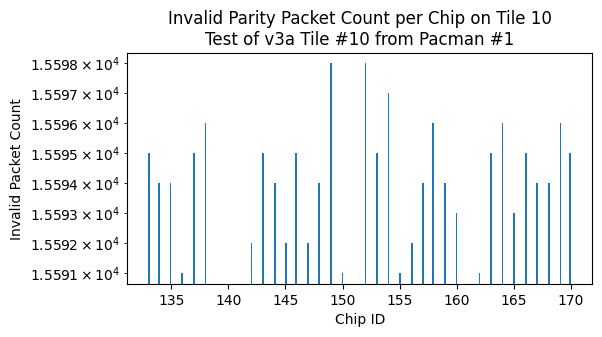

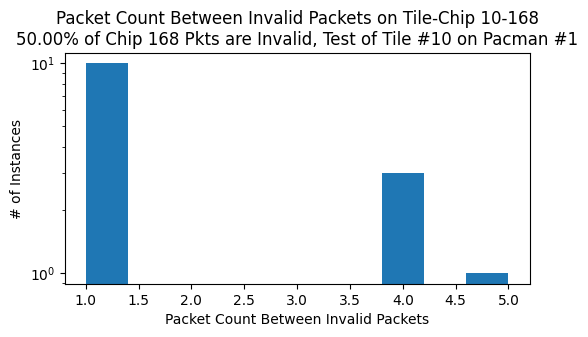

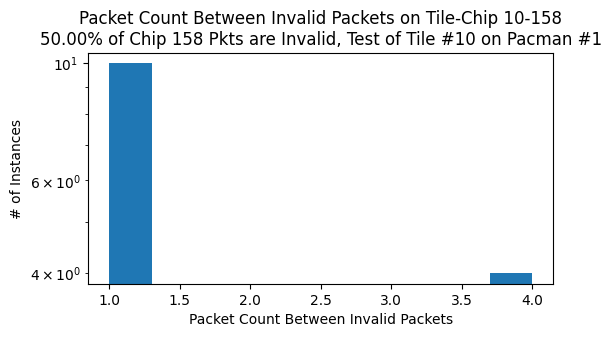

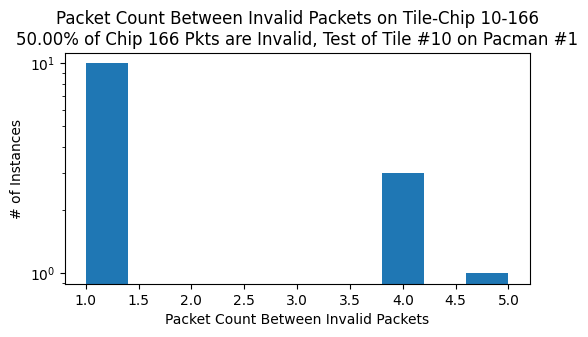

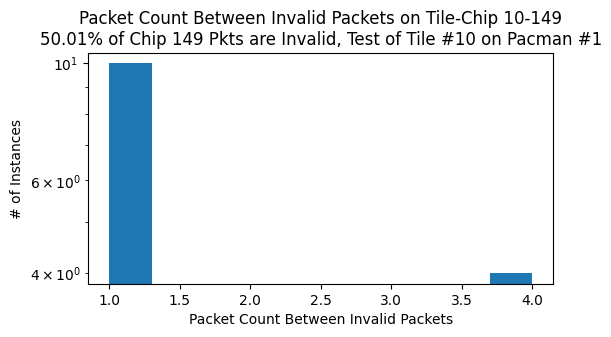

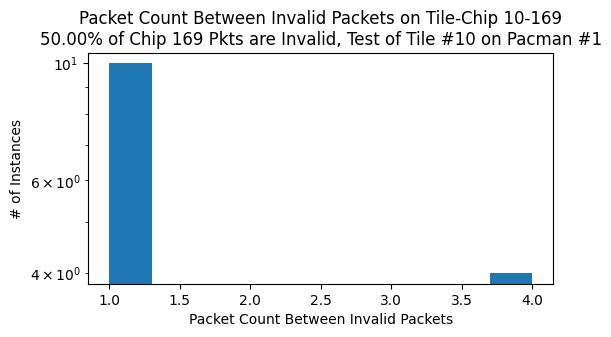

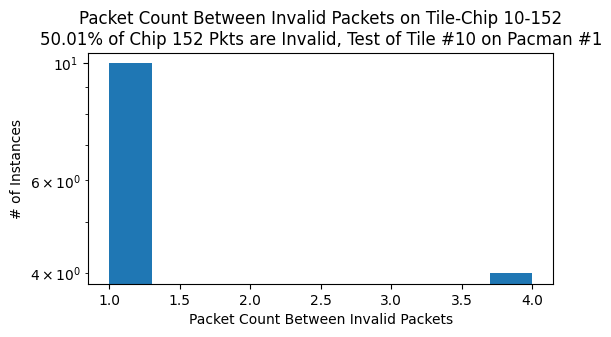

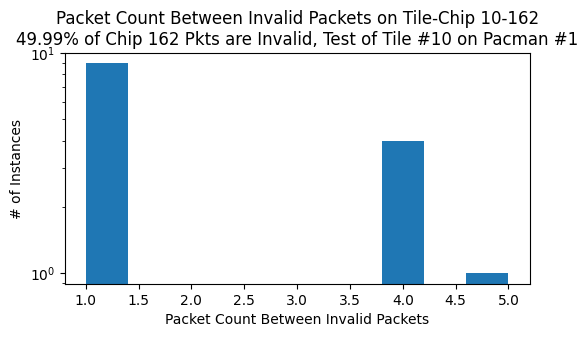

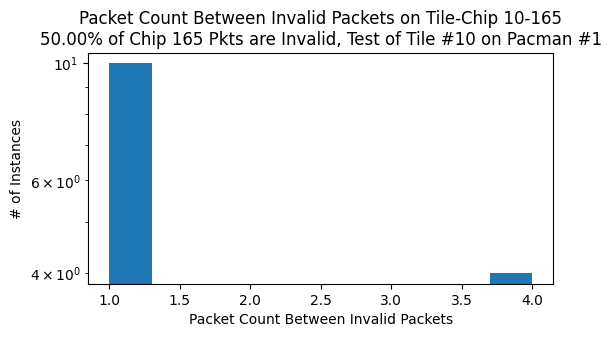

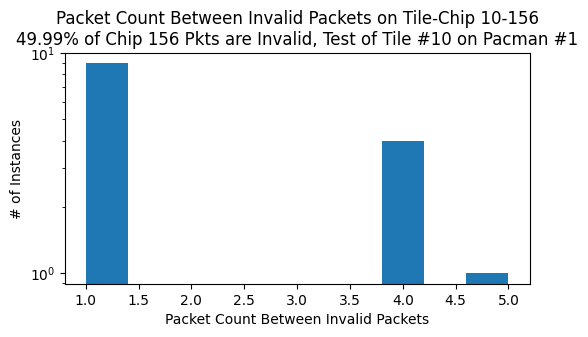

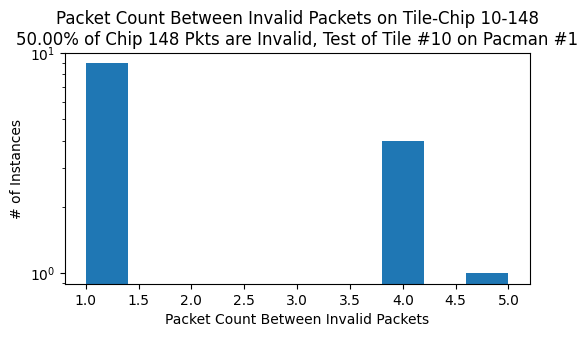

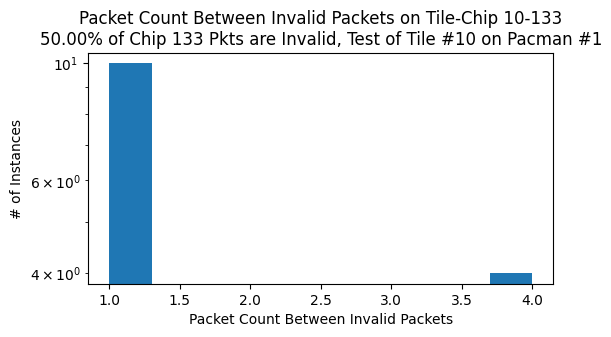

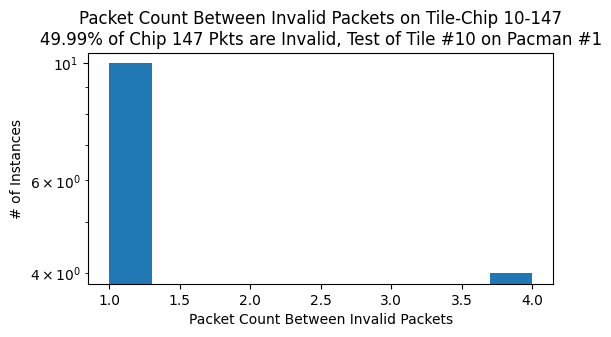

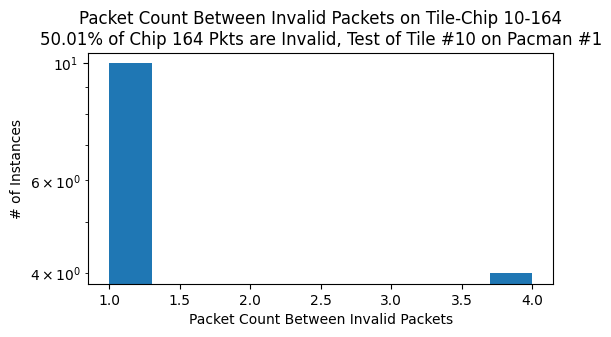

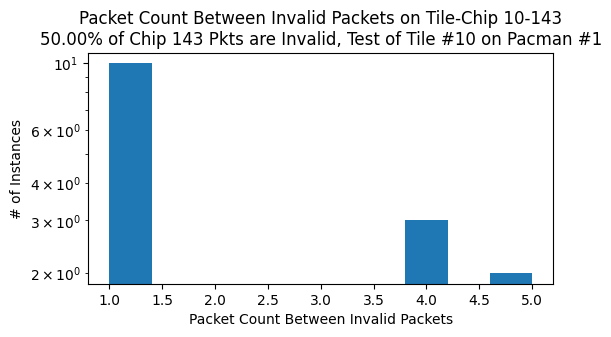

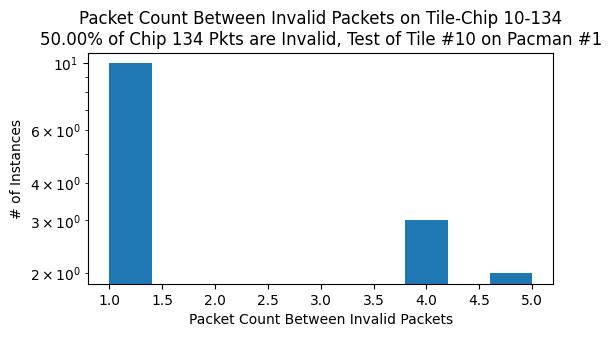

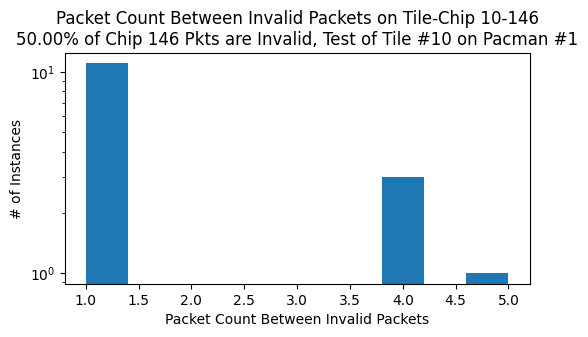

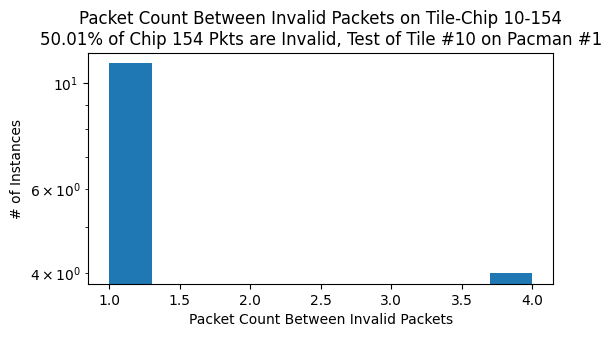

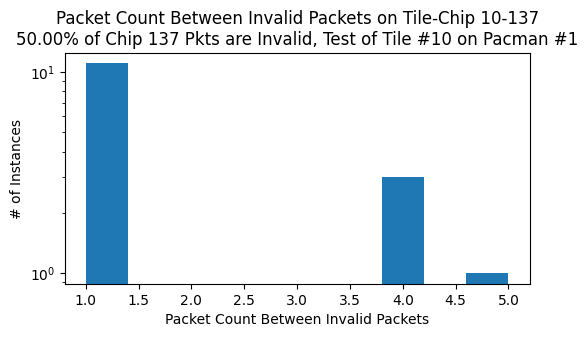

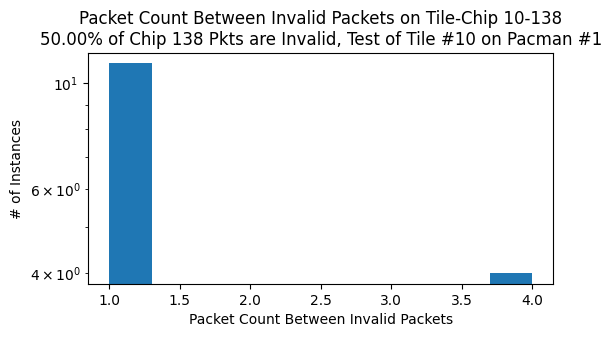

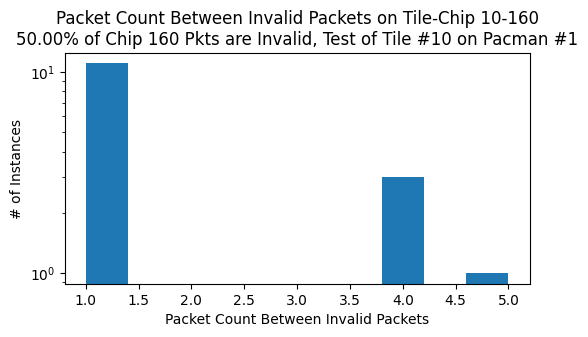

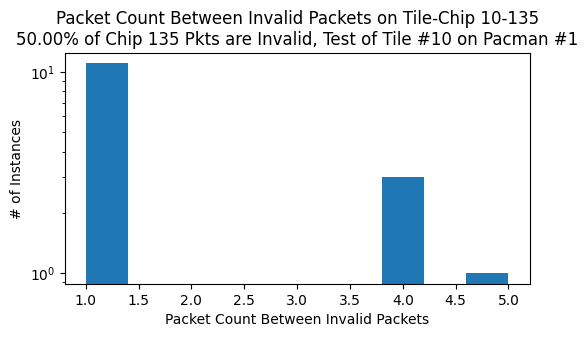

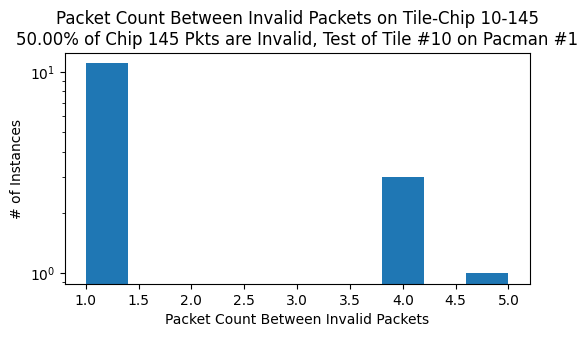

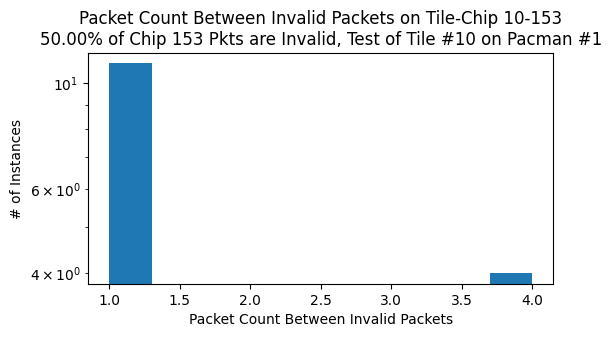

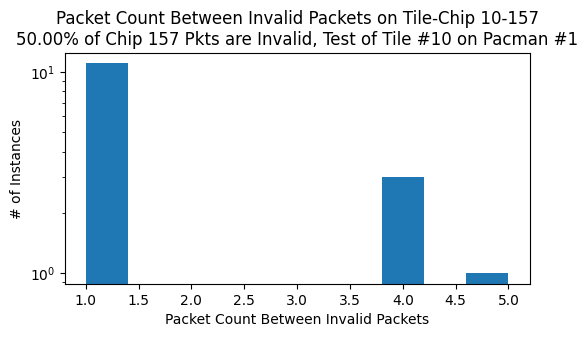

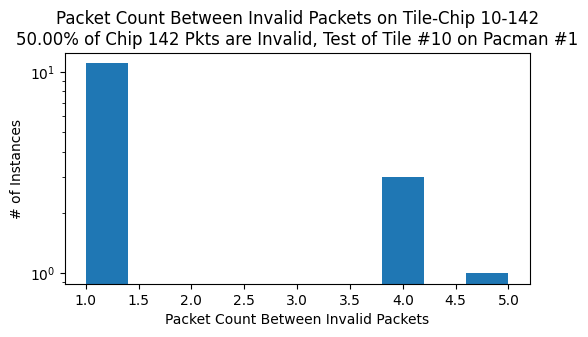

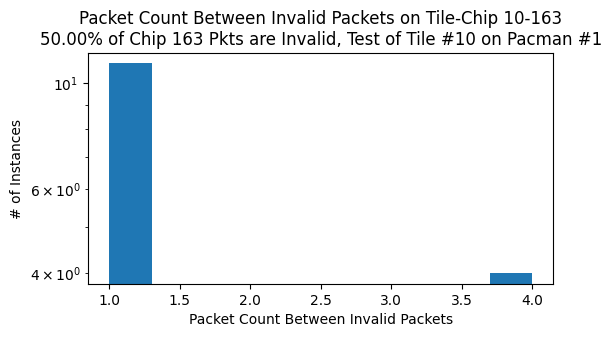

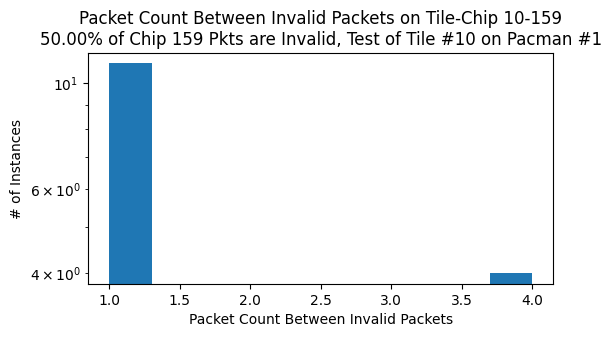

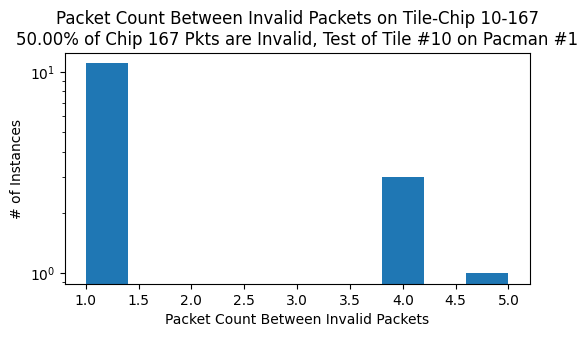

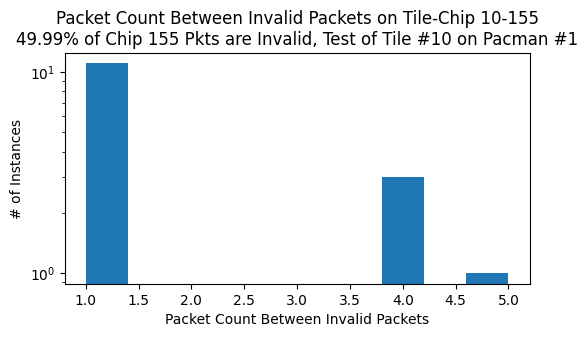

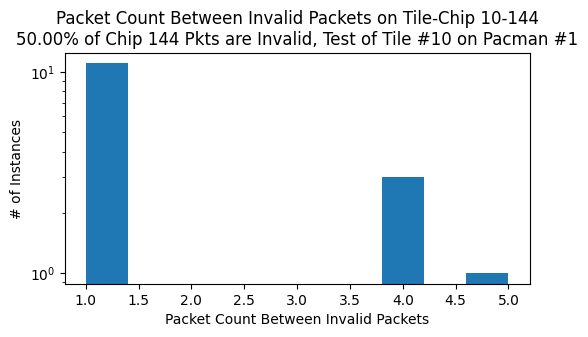

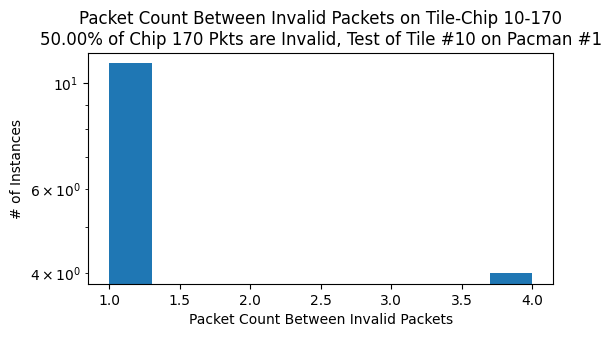

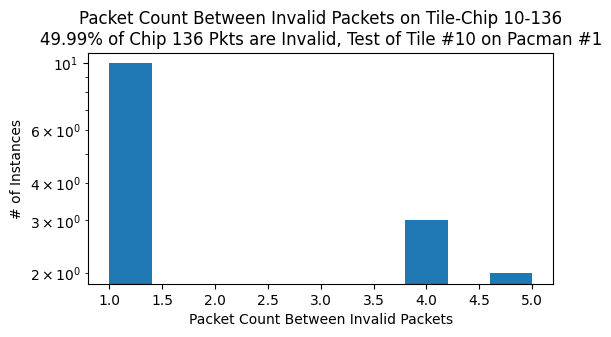

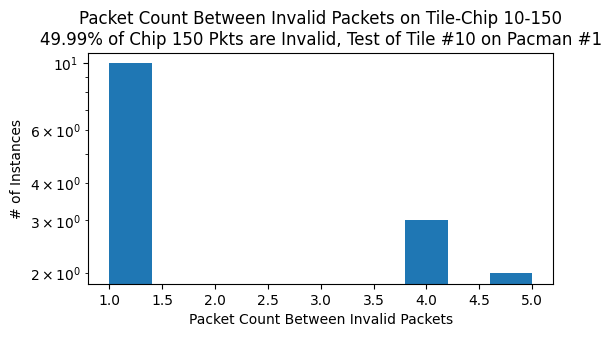

In [7]:
####################
# main
####################


print(f"######################## Run Statistics ############################################")
print(f'\nData File {filename}:')

# get packets from pedestal run data file and check for various attributes
for tile in tiles:
    get_data(filename, tile, ig)
